# PnL Attribution — SPX option, 2026-07-22

Implements **Step 2** (rebuild D, r, F, σ, Greeks every minute from that minute's quotes) and
**Step 3** (Greek PnL attribution) of the ORIE 5254 final project. See `research/problem_definition.md`.

## 0. Inputs

In [1]:
# ---- Option to analyse (pick one) ------------------------------------------
SYMBOL = "SPX   311219P20000000"   # 2031-12-19 Put  K=20000  (Group 8)
# SYMBOL = "SPX   311219C20000000"   # 2031-12-19 Call K=20000  (Group 8)
# SYMBOL = "SPX   270416P02800000"   # 2027-04-16 Put  K=2800
# SYMBOL = "SPX   270416C02800000"   # 2027-04-16 Call K=2800
# SYMBOL = "SPX   281215P03400000"   # 2028-12-15 Put  K=3400
# SYMBOL = "SPX   281215C03400000"   # 2028-12-15 Call K=3400

# ---- Settings --------------------------------------------------------------
DATA_PATH = "../research/opra-pillar-20260722.cbbo-1m.csv.zst"
SETTLEMENT_TIME_ET = "09:30"   # SPX monthlies are AM-settled at the expiry-day open
DAY_COUNT = 365.0              # ACT/365 calendar time for tau
MIN_PAIRS = 3                  # min strikes with two-sided C and P to fit D and F in a minute
RTH_ONLY = False               # True: drop quotes after 16:15 ET

## 1. Load quotes for the option's expiry

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import py_lets_be_rational as lbr

EXPIRY_CODE = SYMBOL[6:12]          # characters 7-12: YYMMDD
CP = SYMBOL[12]                     # character 13: C or P
STRIKE = int(SYMBOL[13:21]) / 1000  # characters 14-21: strike x 1000

expiry_utc = (pd.Timestamp(f"20{EXPIRY_CODE} {SETTLEMENT_TIME_ET}", tz="America/New_York")
              .tz_convert("UTC"))

chunks = pd.read_csv(DATA_PATH, compression="zstd", chunksize=500_000,
                     usecols=["ts_recv", "bid_px_00", "ask_px_00", "symbol"])
q = pd.concat(c[c["symbol"].str[6:12] == EXPIRY_CODE] for c in chunks)

q["ts"] = pd.to_datetime(q["ts_recv"])
q["cp"] = q["symbol"].str[12]
q["K"] = q["symbol"].str[13:21].astype(int) / 1000
if RTH_ONLY:
    q = q[q["ts"].dt.tz_convert("America/New_York").dt.strftime("%H:%M") <= "16:15"]

two_sided = (q["bid_px_00"] > 0) & (q["ask_px_00"] > 0)
q = q[two_sided].copy()
q["mid"] = (q["bid_px_00"] + q["ask_px_00"]) / 2

print(f"{SYMBOL!r}: expiry {expiry_utc}, {'Call' if CP == 'C' else 'Put'}, K={STRIKE:g}")
print(f"{len(q):,} two-sided quotes on this expiry across {q['ts'].nunique()} minutes")

'SPX   311219P20000000': expiry 2031-12-19 14:30:00+00:00, Put, K=20000
28,896 two-sided quotes on this expiry across 450 minutes


## 2. Box rate D(t), r(t) and forward F(t) — per minute, that minute's quotes only

For each minute, take every strike with a two-sided call **and** put, s(K) = C − P.

* **Box:** a box on K₁ < K₂ costs s(K₁) − s(K₂) = D·(K₂ − K₁). Regress box price on width
  across all strike pairs (through the origin) → **D_box**; r = −ln(D_box)/τ.
* **Forward:** s(K) = D·(F − K). OLS of s on K: x-intercept → **F**, slope → −**D_parity** (cross-check).

In [3]:
pairs = q.pivot_table(index=["ts", "K"], columns="cp", values="mid").dropna()
pairs["s"] = pairs["C"] - pairs["P"]

def fit_minute(g: pd.DataFrame) -> pd.Series:
    K, s = g.index.get_level_values("K").to_numpy(), g["s"].to_numpy()
    n = len(K)
    if n < MIN_PAIRS:
        return pd.Series({"n_pairs": n, "D_box": np.nan, "D_parity": np.nan, "F": np.nan})
    i, j = np.triu_indices(n, 1)
    width, box = K[j] - K[i], s[i] - s[j]
    D_box = width @ box / (width @ width)
    slope, intercept = np.polyfit(K, s, 1)
    return pd.Series({"n_pairs": n, "D_box": D_box, "D_parity": -slope, "F": -intercept / slope})

fits = pairs.groupby(level="ts").apply(fit_minute)
fits["tau"] = (expiry_utc - fits.index).total_seconds() / (DAY_COUNT * 86400)
fits["r"] = -np.log(fits["D_box"]) / fits["tau"]
fits.describe().T

,count,mean,std,min,25%,50%,75%,max
n_pairs,450.0,29.526667,8.923104,3.000000,32.000000,34.000000,34.000000,35.000000
D_box,450.0,0.773796,0.000425,0.771476,0.773481,0.773749,0.774086,0.775552
D_parity,450.0,0.773796,0.000425,0.771476,0.773481,0.773749,0.774086,0.775552
F,450.0,9323.211682,10.351480,9282.882015,9318.101960,9322.479133,9330.108463,9343.181373
tau,450.0,5.413384,0.000247,5.412957,5.413170,5.413384,5.413597,5.413811
r,450.0,0.047373,0.000102,0.046951,0.047302,0.047384,0.047448,0.047930


## 3. Implied vol and Black-76 forward Greeks of the option

Undiscounted price = mid / D; σ from `py_lets_be_rational`. Greeks are with respect to **F**,
for V = D·Black76(F, K, σ, τ), D = e^(−rτ):

| Greek | Formula | Units |
|---|---|---|
| delta | D·N(d₁) (call), D·(N(d₁) − 1) (put) | per 1 pt of F |
| gamma | D·φ(d₁) / (F σ √τ) | per pt² |
| vega | D·F·φ(d₁)·√τ | per 1.00 of σ |
| theta | r·V − D·F·φ(d₁)·σ / (2√τ), ÷ DAY_COUNT | per calendar day |
| rho | −τ·V (F held fixed) | per 1.00 of r |

In [4]:
opt = (q[q["symbol"] == SYMBOL].set_index("ts")[["ts_recv", "symbol", "bid_px_00", "ask_px_00", "mid"]]
       .join(fits, how="left"))

q_flag = 1 if CP == "C" else -1

def implied_vol(row) -> float:
    if not np.isfinite(row["F"]) or not np.isfinite(row["D_box"]):
        return np.nan
    undisc = row["mid"] / row["D_box"]
    intrinsic = max(q_flag * (row["F"] - STRIKE), 0.0)
    if undisc <= intrinsic:          # below intrinsic: no Black-76 vol exists
        return np.nan
    return lbr.implied_volatility_from_a_transformed_rational_guess(
        undisc, row["F"], STRIKE, row["tau"], q_flag)

opt["sigma"] = opt.apply(implied_vol, axis=1)

F, D, sig, tau, r, V = (opt[c] for c in ["F", "D_box", "sigma", "tau", "r", "mid"])
d1 = (np.log(F / STRIKE) + 0.5 * sig**2 * tau) / (sig * np.sqrt(tau))
pdf = norm.pdf(d1)
opt["delta"] = D * (norm.cdf(d1) if CP == "C" else norm.cdf(d1) - 1)
opt["gamma"] = D * pdf / (F * sig * np.sqrt(tau))
opt["vega"] = D * F * pdf * np.sqrt(tau)
opt["theta_per_day"] = (r * V - D * F * pdf * sig / (2 * np.sqrt(tau))) / DAY_COUNT
opt["rho"] = -tau * V

print(f"{len(opt)} quoted minutes for the option; sigma solved in {opt['sigma'].notna().sum()}")
opt[["mid", "n_pairs", "D_box", "D_parity", "r", "F", "sigma", "delta", "gamma", "vega", "theta_per_day", "rho"]].describe().T

403 quoted minutes for the option; sigma solved in 402


,count,mean,std,min,25%,50%,75%,max
mid,403.0,8287.503970,9.951339,8272.200000,8280.800000,8286.400000,8290.450000,8327.500000
n_pairs,403.0,32.081886,4.981133,3.000000,33.000000,34.000000,34.000000,35.000000
D_box,403.0,0.773741,0.000413,0.771476,0.773462,0.773678,0.773983,0.775552
D_parity,403.0,0.773741,0.000413,0.771476,0.773462,0.773678,0.773983,0.775552
r,403.0,0.047386,0.000100,0.046951,0.047327,0.047401,0.047453,0.047930
F,403.0,9323.078831,10.844606,9282.882015,9317.632708,9322.253158,9330.696340,9343.181373
sigma,402.0,0.157778,0.003554,0.136503,0.155921,0.157578,0.159283,0.178686
delta,402.0,-0.751226,0.002944,-0.766070,-0.752678,-0.751344,-0.749969,-0.731727
gamma,402.0,0.000015,0.000001,0.000008,0.000014,0.000015,0.000015,0.000021
vega,402.0,1111.956095,106.954799,533.045080,1059.566663,1106.120789,1155.497589,1767.145453


## 4. Step 3 — PnL attribution

Between consecutive quoted minutes of the option (a step can span gaps when the option was not
quoted), using **start-of-step** Greeks:

ΔPrice ≈ delta·ΔF + ½·gamma·ΔF² + vega·Δσ + theta·ΔDays + rho·Δr + residual

In [5]:
prev = opt.shift(1)
opt["gap_min"] = (opt.index.to_series().diff().dt.total_seconds() / 60)
opt["pnl_total"] = opt["mid"].diff()
opt["dDays"] = (prev["tau"] - opt["tau"]) * DAY_COUNT

opt["pnl_delta"] = prev["delta"] * opt["F"].diff()
opt["pnl_gamma"] = 0.5 * prev["gamma"] * opt["F"].diff() ** 2
opt["pnl_vega"] = prev["vega"] * opt["sigma"].diff()
opt["pnl_theta"] = prev["theta_per_day"] * opt["dDays"]
opt["pnl_rho"] = prev["rho"] * opt["r"].diff()

GREEKS = ["pnl_delta", "pnl_gamma", "pnl_vega", "pnl_theta", "pnl_rho"]
opt["pnl_explained"] = opt[GREEKS].sum(axis=1, min_count=len(GREEKS))
opt["pnl_residual"] = opt["pnl_total"] - opt["pnl_explained"].fillna(0)

steps = opt.iloc[1:]
summary = steps[GREEKS + ["pnl_explained", "pnl_residual", "pnl_total"]].sum().to_frame("total")
summary.loc["open_to_close (mid_last - mid_first)"] = opt["mid"].iloc[-1] - opt["mid"].iloc[0]

abs_total = steps["pnl_total"].abs().sum()
pct_residual_form = 1 - steps["pnl_residual"].abs().sum() / abs_total
pct_literal_form = (abs_total - steps["pnl_explained"].abs().sum()) / abs_total

print(f"steps: {len(steps)}  | steps with all inputs: {steps['pnl_explained'].notna().sum()}")
print(f"% PnL explained, 1 - sum|resid|/sum|tickPnL| : {pct_residual_form:.1%}")
print(f"% PnL explained, PDF formula as printed        : {pct_literal_form:.1%}")
summary

steps: 402  | steps with all inputs: 400
% PnL explained, 1 - sum|resid|/sum|tickPnL| : 73.9%
% PnL explained, PDF formula as printed        : 5.1%


,total
pnl_delta,-30.038518
pnl_gamma,0.019779
pnl_vega,-66.376162
pnl_theta,0.288654
pnl_rho,-14.282015
pnl_explained,-111.847071
pnl_residual,75.147071
pnl_total,-36.700000
open_to_close (mid_last - mid_first),-36.700000


## 5. Diagnostics

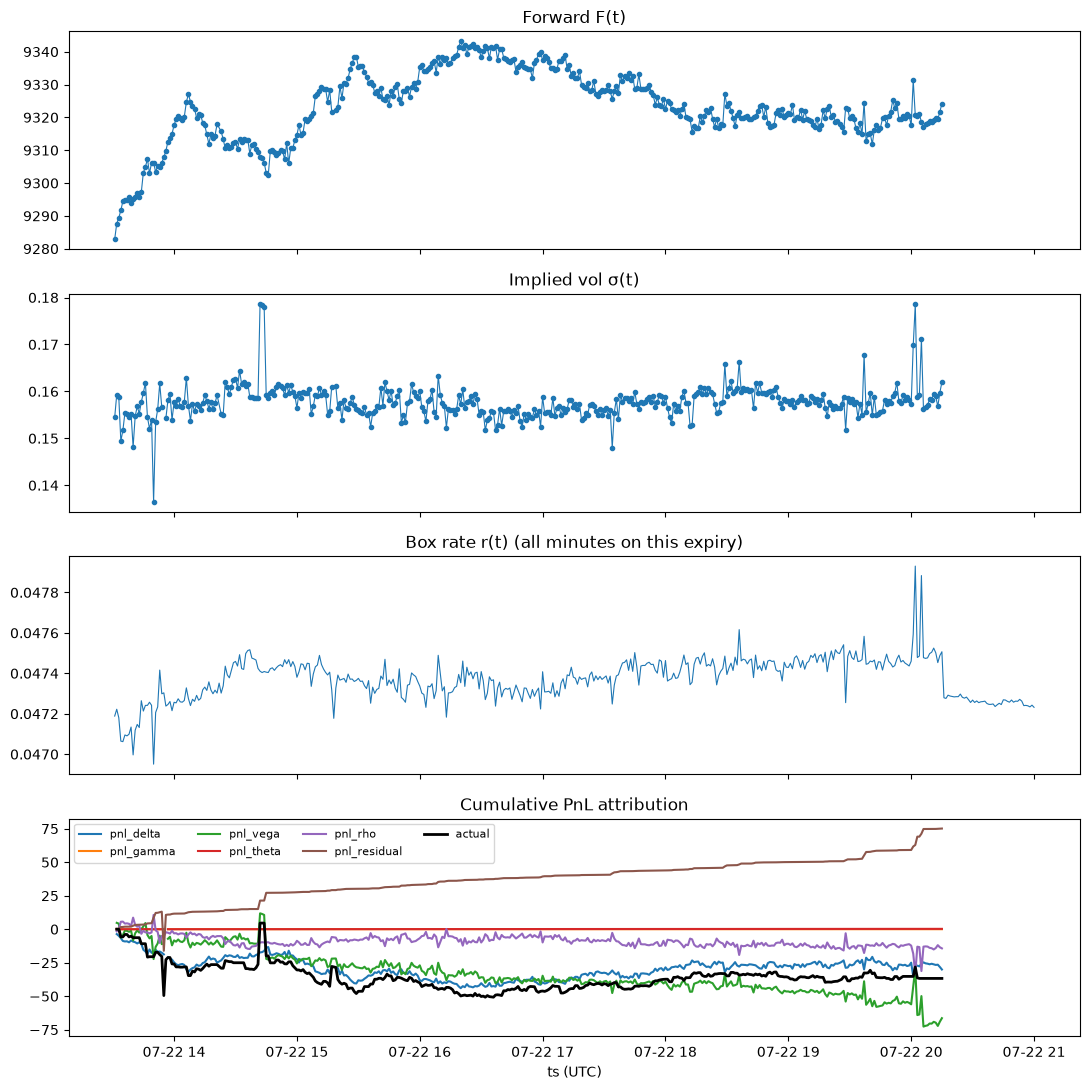

In [6]:
# Plain matplotlib: pandas .plot() uses incompatible x-axis units for regular (fits) vs
# irregular (opt) time indexes, which blanks panels when sharex=True.
fig, ax = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
ax[0].plot(opt.index, opt["F"], marker=".", lw=0.8); ax[0].set_title("Forward F(t)")
ax[1].plot(opt.index, opt["sigma"], marker=".", lw=0.8); ax[1].set_title("Implied vol σ(t)")
ax[2].plot(fits.index, fits["r"], lw=0.8); ax[2].set_title("Box rate r(t) (all minutes on this expiry)")
cum = steps[GREEKS + ["pnl_residual"]].cumsum()
for col in cum:
    ax[3].plot(cum.index, cum[col], label=col)
ax[3].plot(steps.index, steps["pnl_total"].cumsum(), color="k", lw=2, label="actual")
ax[3].set_title("Cumulative PnL attribution"); ax[3].legend(ncol=4, fontsize=8)
ax[3].set_xlabel("ts (UTC)")
plt.tight_layout()